In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark)
np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    39.323964
1           NaN   80.793547      78.411768    42.282153
2           NaN   81.572855      86.245769    44.868699
3           NaN   76.977227      85.807031    44.277604
4           NaN   83.387143      49.334959    37.148981
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    39.613708
96     5.592241   76.161426      83.493998    42.343348
97     5.522111   86.537251      74.609493    43.644129
98     5.010227  -10.000000      82.192932    44.618326
99    50.000000   73.570297      79.444433    40.225388

[100 rows x 4 columns]


In [4]:
#Part A, Question 1

import pandas as pd
import numpy as np

df = pd.read_csv("student_data.csv")

valid_hours = df.loc[df["study_hours"] != 50, "study_hours"].dropna()

Q1 = valid_hours.quantile(0.25)
Q3 = valid_hours.quantile(0.75)
IQR = Q3 - Q1
upper_fence = Q3 + 1.5 * IQR

clean = df.copy()
clean.loc[clean["study_hours"] == 50, "study_hours"] = upper_fence

clean["study_hours"] = clean["study_hours"].fillna(
    valid_hours.median()
)

clean.loc[clean["attendance"] < 0, "attendance"] = np.nan
clean["attendance"] = clean["attendance"].fillna(
    clean["attendance"].median()
)

print(clean.head())
print(clean.isna().sum())


   study_hours  attendance  previous_mark  final_score
0     4.768703   70.846293      75.366810    39.323964
1     4.768703   80.793547      78.411768    42.282153
2     4.768703   81.572855      86.245769    44.868699
3     4.768703   76.977227      85.807031    44.277604
4     4.768703   83.387143      49.334959    37.148981
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64


In [5]:
#Part A, Question 2
print("Shape:", clean.shape)
print("Columns:", clean.columns.tolist())
print("Data types:\n", clean.dtypes)


Shape: (100, 4)
Columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Data types:
 study_hours      float64
attendance       float64
previous_mark    float64
final_score      float64
dtype: object


In [6]:
#Part B, Question 1

summary = clean.agg(["mean", "median", "std"]).T

print(summary.round(3))

                 mean  median     std
study_hours     4.779   4.769   1.819
attendance     85.227  85.997   9.537
previous_mark  70.973  71.465  16.264
final_score    42.158  42.259   4.396


In [7]:
#Part B, Question 2
print("1. Study hours: Students study approximately 4.78 hours on average. The standard deviation of 1.82 indicates that study hours vary around the mean, but most students do not have extremely different study times after cleaning.")
print("2. Attendance: The average attendance is approximately 85.23. The standard deviation of 9.54 suggests that attendance varies between students, although many students attend a relatively similar proportion of classes.")
print("3. Previous marks and final scores: Previous marks have a standard deviation of 16.26, compared with 6.09 for final scores. This indicates that previous marks are more widely spread, while final scores are more closely clustered around their mean.")

1. Study hours: Students study approximately 4.78 hours on average. The standard deviation of 1.82 indicates that study hours vary around the mean, but most students do not have extremely different study times after cleaning.
2. Attendance: The average attendance is approximately 85.23. The standard deviation of 9.54 suggests that attendance varies between students, although many students attend a relatively similar proportion of classes.
3. Previous marks and final scores: Previous marks have a standard deviation of 16.26, compared with 6.09 for final scores. This indicates that previous marks are more widely spread, while final scores are more closely clustered around their mean.


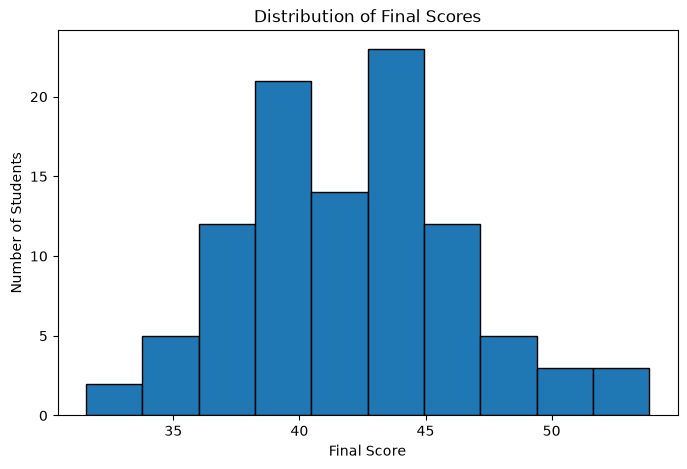

In [8]:
#Part C, Question 1

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(clean["final_score"], bins=10, edgecolor="black")

plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Scores")

plt.show()

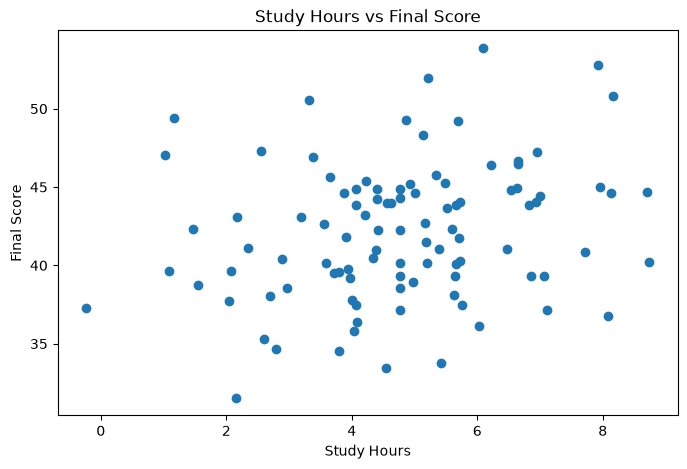

In [9]:
#Part C, Question 2

plt.figure(figsize=(8, 5))

plt.scatter(
    clean["study_hours"],
    clean["final_score"]
)

plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.title("Study Hours vs Final Score")

plt.show()

In [10]:
#Part D, Question 1

correlation = clean["study_hours"].corr(
    clean["final_score"],
    method="pearson"
)

print("Pearson correlation:", round(correlation, 4))

Pearson correlation: 0.2366


In [11]:
#Part D, Question 2

print("No. Correlation does not guarantee an individual student's score. Two students can study for the same number of hours and receive different scores.")
print("Potential confounding variables include: Previous marks, Attendance, Study quality, Sleep and exam preparation")
print("correlation alone does not establish causation: it describes an association, not proof that one variable causes another.")

No. Correlation does not guarantee an individual student's score. Two students can study for the same number of hours and receive different scores.
Potential confounding variables include: Previous marks, Attendance, Study quality, Sleep and exam preparation
correlation alone does not establish causation: it describes an association, not proof that one variable causes another.


In [12]:
#Part E, Question 1-3

# Select one student, excluding the target variable
x = clean.loc[
    6,
    ["study_hours", "attendance", "previous_mark"]
].to_numpy()

# Define the weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate the dot product and add the bias
y = np.dot(w, x) + b

print("Feature vector x:", x)
print("Weight vector w:", w)
print("Predicted value y:", y)


Feature vector x: [  8.15842563 103.86185901  77.72552901]
Weight vector w: [0.5 0.2 0.4]
Predicted value y: 60.94179622118041


In [13]:
#Part E, Question 4
print("f{w} is the weight vector represents how much each feature contributes to the output")
print("The bias(b) is the constant added after calculating the weighted sum. It allows the output to be shifted up or down instead of forcing the prediction to pass through zero.")

f{w} is the weight vector represents how much each feature contributes to the output
The bias(b) is the constant added after calculating the weighted sum. It allows the output to be shifted up or down instead of forcing the prediction to pass through zero.


In [14]:
#Part F, Question 1

scaled = clean.copy()

for column in ["study_hours", "previous_mark"]:
    mean = clean[column].mean()
    std = clean[column].std(ddof=0)

    scaled[column + "_standardized"] = (
        clean[column] - mean
    ) / std

print(
    scaled[
        [
            "study_hours",
            "previous_mark",
            "study_hours_standardized",
            "previous_mark_standardized"
        ]
    ].head(10).round(3)
)


   study_hours  previous_mark  study_hours_standardized  \
0        4.769         75.367                    -0.006   
1        4.769         78.412                    -0.006   
2        4.769         86.246                    -0.006   
3        4.769         85.807                    -0.006   
4        4.769         49.335                    -0.006   
5        4.769         55.933                    -0.006   
6        8.158         77.726                     1.867   
7        6.535         77.707                     0.970   
8        4.061         77.726                    -0.397   
9        6.085        127.791                     0.721   

   previous_mark_standardized  
0                       0.271  
1                       0.460  
2                       0.944  
3                       0.917  
4                      -1.337  
5                      -0.929  
6                       0.417  
7                       0.416  
8                       0.417  
9                       3.511 

In [15]:
#Part E, Question 2
print("The study-hours range includes the outlier, which is why cleaning it first is important.Even after cleaning, previous marks generally have a much wider numerical spread than study hours. Without scaling, differences in previous marks could dominate the distance calculation.")
print("For example, suppose two students differ by 1 study hour but 20 previous-mark points. The previous-mark difference contributes much more to Euclidean distance simply because of its scale.Standardization puts both features on a comparable scale, helping KNN consider both when calculating distances.")

The study-hours range includes the outlier, which is why cleaning it first is important.Even after cleaning, previous marks generally have a much wider numerical spread than study hours. Without scaling, differences in previous marks could dominate the distance calculation.
For example, suppose two students differ by 1 study hour but 20 previous-mark points. The previous-mark difference contributes much more to Euclidean distance simply because of its scale.Standardization puts both features on a comparable scale, helping KNN consider both when calculating distances.
